<a href="https://colab.research.google.com/github/rivindu02/parameter-efficient-finetuning/blob/main/part1_vlm_dora/run_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Part 1 — Does DoRA's learning pattern transfer to a vision-language model?

**Paper claim (DoRA, Liu et al. 2024, Fig. 2):** decompose each weight into magnitude and direction. Across layers and
checkpoints, full fine-tuning shows a **negative** correlation between magnitude change ΔM and direction change ΔD; LoRA
shows a **positive** one; DoRA's pattern resembles full fine-tuning (negative).

**Hypothesis:** the same holds when SmolVLM-256M is fine-tuned on DocVQA — in the language model *and* in the vision
encoder (bonus: per-tower analysis: vision encoder / connector / LM).

Setup: SmolVLM-256M-Instruct · DocVQA subset (2000 train / 300 validation) · LoRA vs DoRA (r=8, α=16) vs full FT on the
same targets (q,k,v,o of both towers + connector) · 1 epoch · ΔM/ΔD recorded at 8 checkpoints · ANLS for accuracy.
Runtime: T4 GPU. Each training run ≈ 15–30 min; every result is saved to Drive, so cells can be re-run after a disconnect.

In [1]:
# ---- config: code comes from GitHub, results go to Google Drive ----
REPO_URL = 'https://github.com/rivindu02/parameter-efficient-finetuning.git'   # <- your repo
BRANCH = 'main'

!pip -q install -U "transformers>=4.46" peft accelerate datasets
import os, sys, subprocess
from google.colab import drive
drive.mount('/content/drive')
OUT = '/content/drive/MyDrive/EN4554/part1_vlm_dora'
os.makedirs(OUT, exist_ok=True)
url = REPO_URL
try:  # private repo: add a Colab secret GH_TOKEN (read-only fine-grained token) with notebook access
    from google.colab import userdata
    url = REPO_URL.replace('https://', f"https://{userdata.get('GH_TOKEN')}@")
except Exception:
    pass
if not os.path.exists('/content/repo/.git'):
    subprocess.run(['git', 'clone', '-q', '-b', BRANCH, url, '/content/repo'], check=True)
else:
    subprocess.run(['git', '-C', '/content/repo', 'fetch', '-q', 'origin', BRANCH], check=True)
    subprocess.run(['git', '-C', '/content/repo', 'reset', '-q', '--hard', f'origin/{BRANCH}'], check=True)
print(subprocess.run(['git', '-C', '/content/repo', 'log', '-1', '--oneline'], capture_output=True, text=True).stdout)
%cd /content/repo/part1_vlm_dora
sys.path.insert(0, '/content/repo/part1_vlm_dora')
SEED = 42
print('outputs ->', OUT)

MODULES = ['dora_vlm']
!pip -q install matplotlib

Mounted at /content/drive
768f58c part1_vlm_dora: Update part1_dora_vlm.ipynb

/content/repo/part1_vlm_dora
outputs -> /content/drive/MyDrive/EN4554/part1_vlm_dora


In [2]:
# re-run after pushing code changes: syncs to the latest commit (fetch + reset) and reloads modules
import importlib, subprocess
subprocess.run(['git', '-C', '/content/repo', 'fetch', '-q', 'origin', BRANCH], check=True)
subprocess.run(['git', '-C', '/content/repo', 'reset', '-q', '--hard', f'origin/{BRANCH}'], check=True)
print(subprocess.run(['git', '-C', '/content/repo', 'log', '-1', '--oneline'], capture_output=True, text=True).stdout)
for m in list(sys.modules):
    if m in MODULES: importlib.reload(sys.modules[m])

768f58c part1_vlm_dora: Update part1_dora_vlm.ipynb



## 1. Config + data subset (cached as JPEG on local disk)

In [3]:
import json, os, torch, gc
import dora_vlm as dv
SMOKE = False   # True: tiny run (16 train / 8 eval, ~5 min) to check the pipeline end to end
if SMOKE:
    cfg = dv.Config(out_dir=OUT + '/smoke', data_dir='/content/data_docvqa_smoke', seed=SEED,
                    n_train=16, n_eval=8, n_snapshots=2, eval_batch=4)
else:
    cfg = dv.Config(out_dir=OUT, data_dir='/content/data_docvqa', seed=SEED)
print(cfg)
dv.prepare_data(cfg)
dv.show_masking(cfg)   # only the answer tokens should be supervised

Config(model_id='HuggingFaceTB/SmolVLM-256M-Instruct', dataset='HuggingFaceM4/DocumentVQA', train_split='train', eval_split='validation', n_train=2000, n_eval=300, data_dir='/content/data_docvqa', out_dir='/content/drive/MyDrive/EN4554/part1_vlm_dora', image_longest_edge=1024, seed=42, epochs=1, batch_size=8, micro_batch=4, rank=8, alpha=16, dropout=0.05, lr_adapter=0.0001, lr_full=1e-05, targets='all', allow_cpu=False, n_snapshots=8, max_new_tokens=24, eval_batch=16, extra={})


README.md:   0%|          | 0.00/806 [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/38 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/17 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/17 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/38 [00:00<?, ?it/s]

... (21 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/136 [00:00<?, ?B/s]

seq len 372, supervised 7 tokens: ' 7.0`<end_of_utterance>\n'
seq len 366, supervised 9 tokens: ' R.J. Reynolds Tobacco Company<end_of_utterance>\n'


## 2. Zero-shot baseline

In [ ]:
if dv.needs_eval(cfg, 'zeroshot'):
    model, proc = dv.load_model_and_processor(cfg)
    dv.evaluate_anls(cfg, model.to('cuda'), proc, 'zeroshot')
    del model; gc.collect(); torch.cuda.empty_cache()

Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

[zeroshot] ANLS 52.17  EM 25.67  (ignoring trailing punctuation: ANLS 55.04  EM 43.00)  n=300


## 3. Training runs (one cell each, skipped if results already on Drive)

In [ ]:
if not os.path.exists(os.path.join(cfg.out_dir, 'stats_lora.json')):      # train (+ evaluate)
    model, proc = dv.train_method(cfg, 'lora')
    dv.evaluate_anls(cfg, model, proc, 'lora')
    del model; gc.collect(); torch.cuda.empty_cache()
elif dv.needs_eval(cfg, 'lora'):                                         # already trained: re-evaluate only
    model, proc = dv.load_trained(cfg, 'lora')
    dv.evaluate_anls(cfg, model, proc, 'lora')
    del model; gc.collect(); torch.cuda.empty_cache()
else:
    print('lora: trained and evaluated already')

Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/peft/import_utils.py:195: UserWarning: Found an incompatible version of torchao. Found version 0.10.0, but only versions above 0.16.0 are supported. torchao support in PEFT is disabled; if you want to use a torchao-quantized model with PEFT, please upgrade torchao.
  warnings.warn(


[lora] ANLS 56.73  EM 46.00  (ignoring trailing punctuation: ANLS 57.12  EM 47.00)  n=300


In [ ]:
if not os.path.exists(os.path.join(cfg.out_dir, 'stats_dora.json')):      # train (+ evaluate)
    model, proc = dv.train_method(cfg, 'dora')
    dv.evaluate_anls(cfg, model, proc, 'dora')
    del model; gc.collect(); torch.cuda.empty_cache()
elif dv.needs_eval(cfg, 'dora'):                                         # already trained: re-evaluate only
    model, proc = dv.load_trained(cfg, 'dora')
    dv.evaluate_anls(cfg, model, proc, 'dora')
    del model; gc.collect(); torch.cuda.empty_cache()
else:
    print('dora: trained and evaluated already')

Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

[dora] ANLS 57.50  EM 46.33  (ignoring trailing punctuation: ANLS 57.52  EM 46.67)  n=300


In [ ]:
if not os.path.exists(os.path.join(cfg.out_dir, 'stats_full.json')):      # train (+ evaluate)
    model, proc = dv.train_method(cfg, 'full')
    dv.evaluate_anls(cfg, model, proc, 'full')
    del model; gc.collect(); torch.cuda.empty_cache()
elif dv.needs_eval(cfg, 'full'):                                         # already trained: re-evaluate only
    model, proc = dv.load_trained(cfg, 'full')
    dv.evaluate_anls(cfg, model, proc, 'full')
    del model; gc.collect(); torch.cuda.empty_cache()
else:
    print('full: trained and evaluated already')

Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3204: FutureWarning: `gradient_checkpointing_enable` is deprecated and will be removed in v6. Use `activation_checkpointing_enable` instead.
  warnings.warn(


tracking 169 weight matrices (48 vision, 1 connector, 120 text)


[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`...


[full] step 1/250 loss 3.1189 4s


/content/repo/part1_vlm_dora/dora_vlm.py:307: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


[full] step 10/250 loss 1.6398 40s
[full] step 20/250 loss 0.9438 81s
[full] step 30/250 loss 0.3393 123s
[full] step 40/250 loss 1.0139 166s
[full] step 50/250 loss 0.4426 209s
[full] step 60/250 loss 0.5725 252s
[full] step 70/250 loss 0.3861 296s
[full] step 80/250 loss 0.2065 339s
[full] step 90/250 loss 0.5224 382s
[full] step 100/250 loss 0.7784 425s
[full] step 110/250 loss 0.3365 468s
[full] step 120/250 loss 1.1425 511s
[full] step 130/250 loss 0.4087 555s
[full] step 140/250 loss 0.1817 598s
[full] step 150/250 loss 0.5214 641s
[full] step 160/250 loss 0.6357 685s
[full] step 170/250 loss 0.4020 728s
[full] step 180/250 loss 0.7890 770s
[full] step 190/250 loss 0.2271 814s
[full] step 200/250 loss 0.2387 856s
[full] step 210/250 loss 0.3024 899s
[full] step 220/250 loss 0.5238 942s
[full] step 230/250 loss 0.3749 986s
[full] step 240/250 loss 0.4683 1029s
[full] step 250/250 loss 0.5251 1071s


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[full] done in 1084s; stats + weights in /content/drive/MyDrive/EN4554/part1_vlm_dora
[full] ANLS 57.07  EM 45.00  (ignoring trailing punctuation: ANLS 56.96  EM 45.67)  n=300


## 4. Accuracy: zero-shot vs adapted

In [4]:
rows = []
for n in ['zeroshot', 'lora', 'dora', 'full']:
    p = os.path.join(OUT, f'eval_{n}.json')
    if os.path.exists(p):
        r = json.load(open(p))
        rows.append((n, r['anls'], r['exact_match'], r.get('anls_norm', float('nan')), r.get('exact_match_norm', float('nan'))))
print(f"{'model':<10}{'ANLS':>8}{'EM':>8}{'ANLS*':>8}{'EM*':>8}   (* ignoring trailing punctuation)")
for n, a, e, a2, e2 in rows: print(f'{n:<10}{a:>8.2f}{e:>8.2f}{a2:>8.2f}{e2:>8.2f}')

model         ANLS      EM   ANLS*     EM*   (* ignoring trailing punctuation)
zeroshot     52.17   25.67   55.04   43.00
lora         56.73   46.00   57.12   47.00
dora         57.50   46.33   57.52   46.67
full         57.07   45.00   56.96   45.67


## 5. Claim test: ΔM vs ΔD correlation
`r_pooled`: all (layer, checkpoint) points, as in the paper's Fig. 2. `r_within`: mean across-layer correlation per checkpoint
(removes the trivial "both grow over time" trend). Paper's prediction: **full < 0, LoRA > 0, DoRA < 0**.
First q/v projections (the modules analysed in the paper), then all projections.

In [5]:
corr_qv = dv.analyze(OUT, proj_filter=('q_proj', 'v_proj'))


== full ==  group                     n  r_pooled  rho_pooled  r_within   r_final
          ALL                     680     0.241       0.376     0.145     0.214
          connector/ALL             8     0.996       0.976       nan       nan
          connector/proj            8     0.996       0.976       nan       nan
          text/ALL                480     0.038       0.401    -0.014    -0.049
          text/q_proj             240    -0.018       0.155    -0.257    -0.255
          text/v_proj             240     0.119       0.313     0.128    -0.038
          vision/ALL              192     0.142       0.338    -0.219    -0.193
          vision/q_proj            96     0.187       0.340    -0.703    -0.693
          vision/v_proj            96     0.911       0.937     0.845     0.847

== lora ==  group                     n  r_pooled  rho_pooled  r_within   r_final
          ALL                     680    -0.438      -0.400    -0.548    -0.589
          connector/ALL           

In [6]:
corr_all = dv.analyze(OUT, proj_filter=None)
json.dump({'qv': corr_qv, 'all': corr_all}, open(os.path.join(OUT, 'correlations.json'), 'w'), indent=1)


== full ==  group                     n  r_pooled  rho_pooled  r_within   r_final
          ALL                    1352     0.158       0.263     0.063     0.124
          connector/ALL             8     0.996       0.976       nan       nan
          connector/proj            8     0.996       0.976       nan       nan
          text/ALL                960     0.071       0.308     0.024     0.000
          text/k_proj             240     0.030       0.376    -0.083    -0.076
          text/o_proj             240     0.601       0.209     0.621     0.557
          text/q_proj             240    -0.018       0.155    -0.257    -0.255
          text/v_proj             240     0.119       0.313     0.128    -0.038
          vision/ALL              384     0.070       0.251    -0.298    -0.263
          vision/k_proj            96     0.091       0.400    -0.706    -0.668
          vision/o_proj            96     0.922       0.865     0.832     0.863
          vision/q_proj            96

## 6. Fig. 2-style scatter plots, per tower

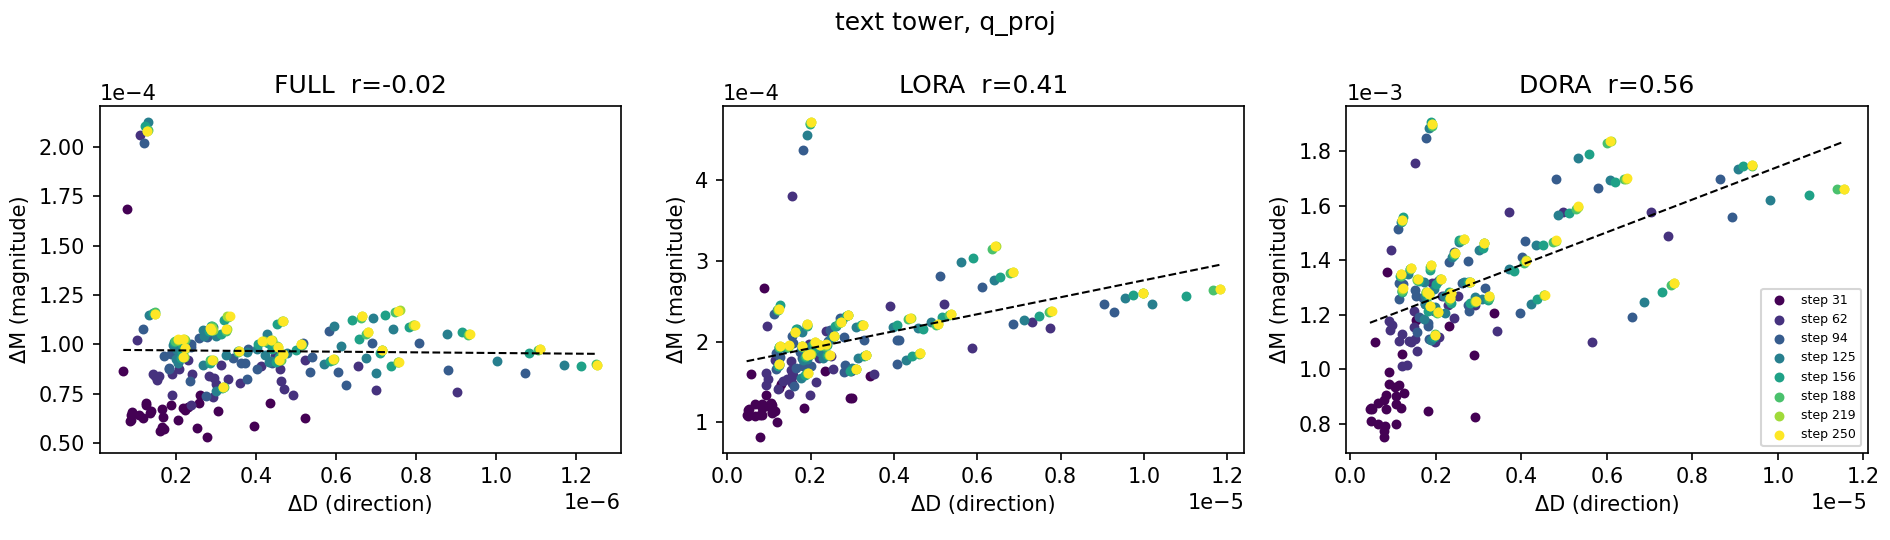

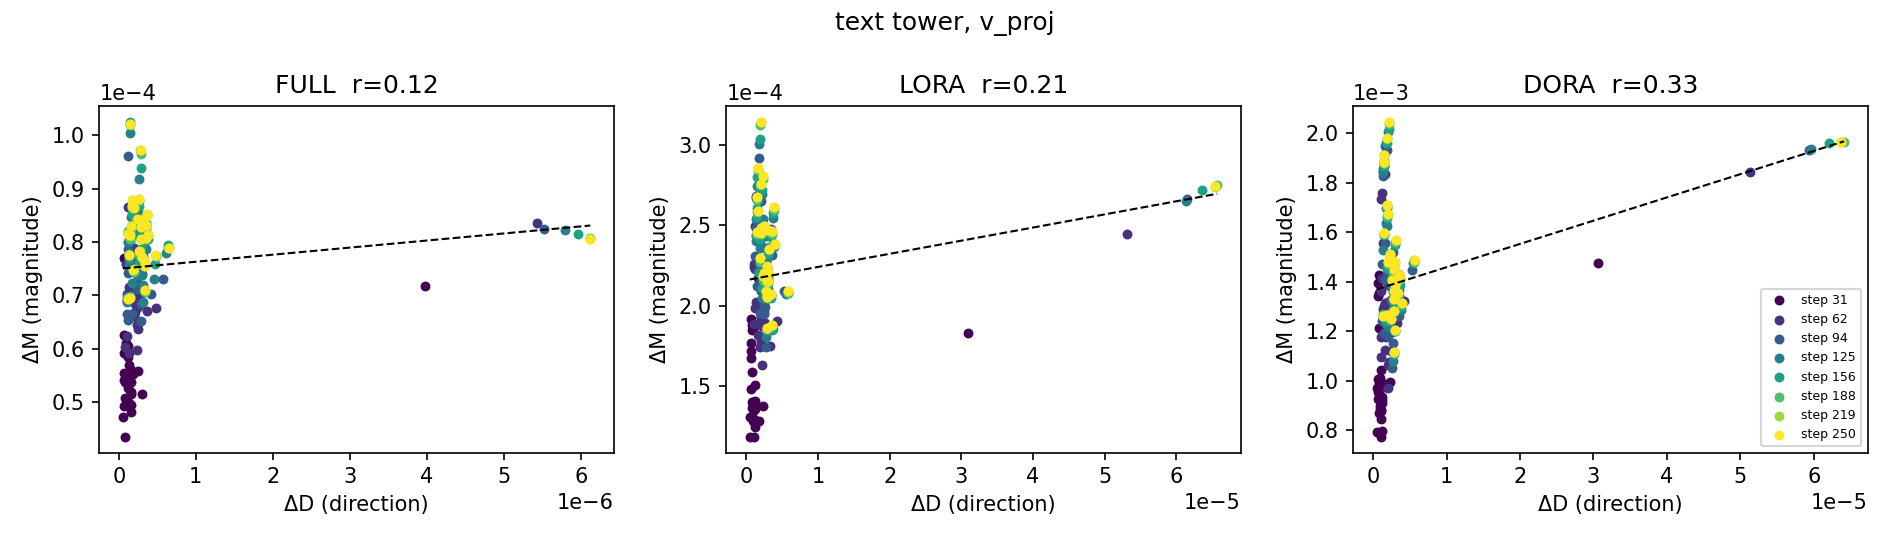

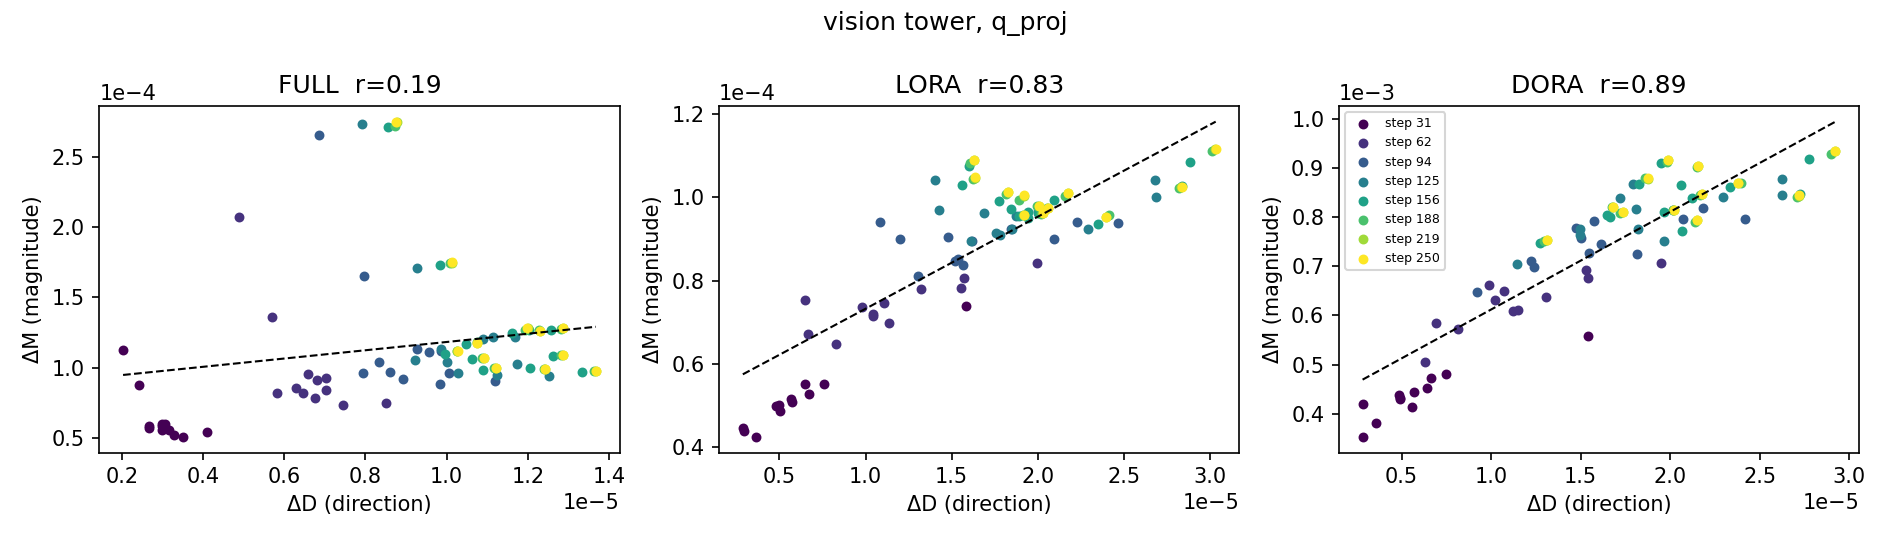

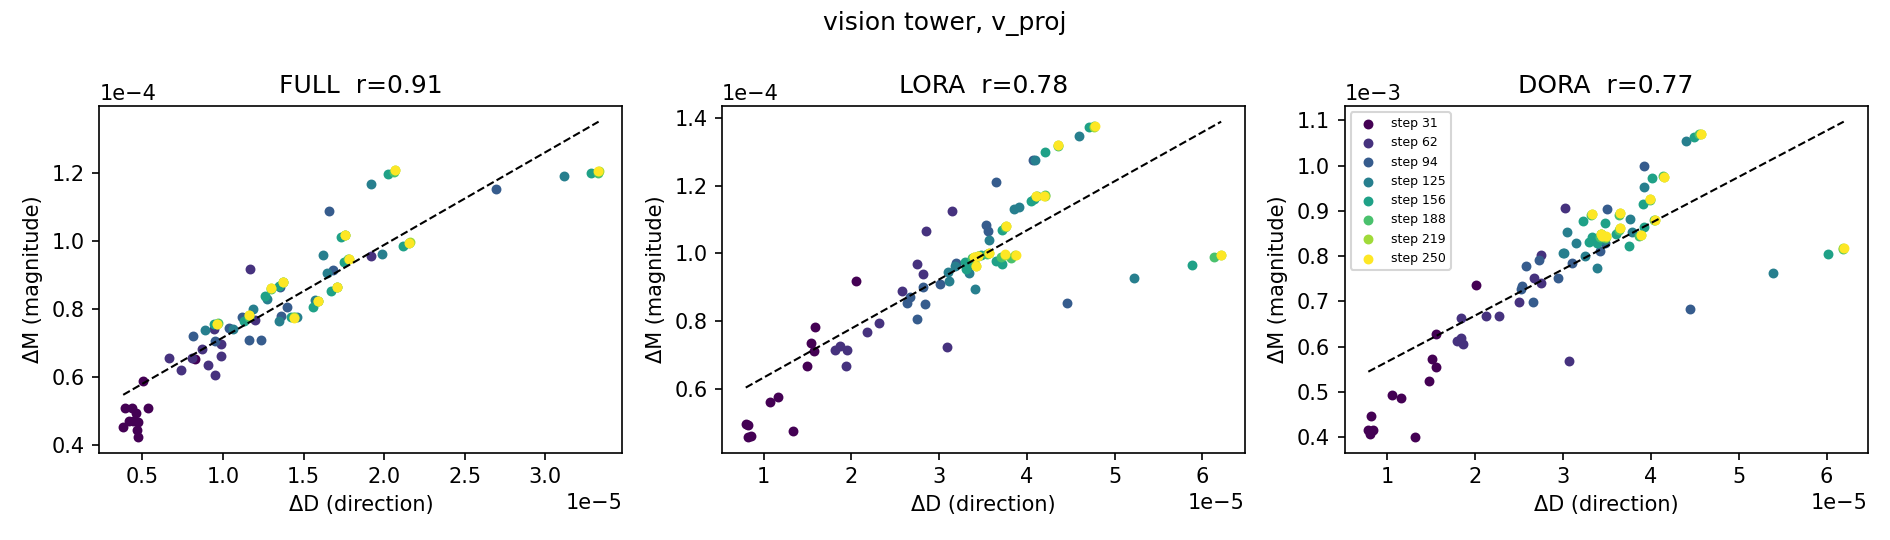

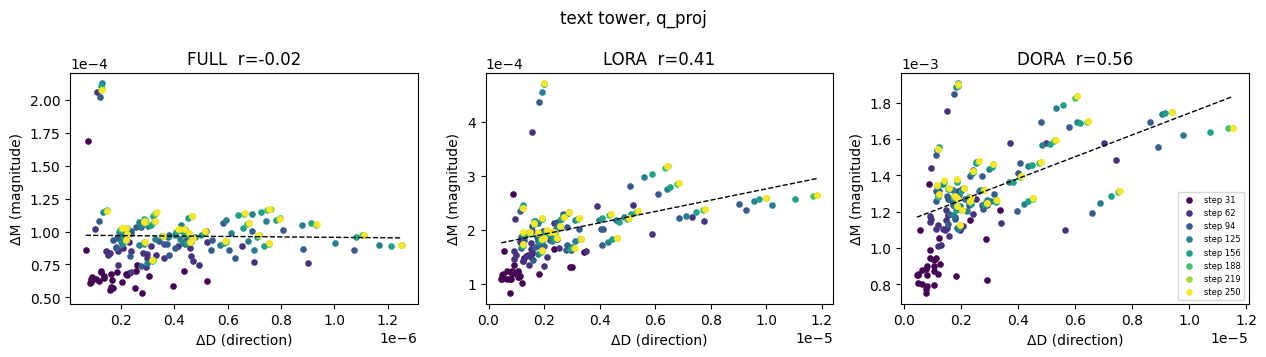

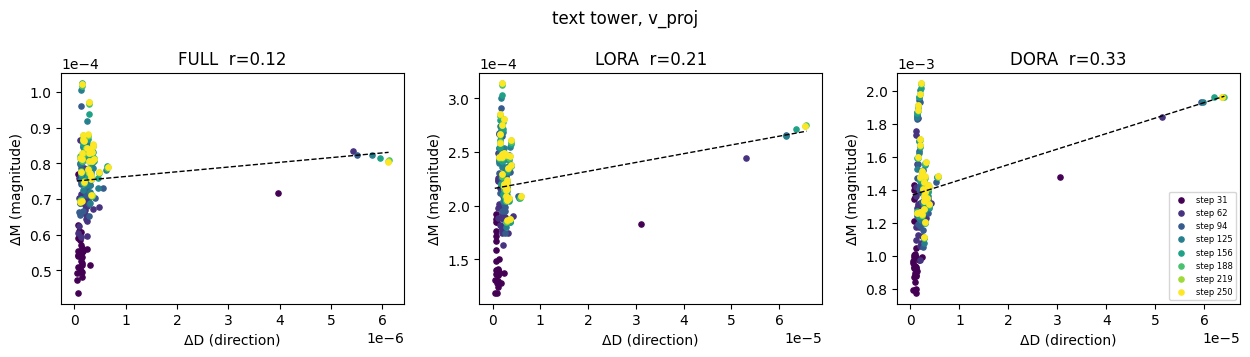

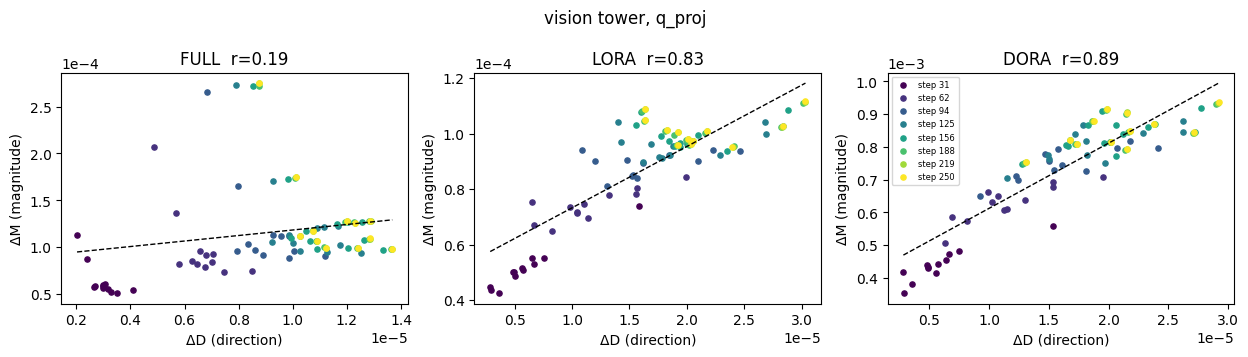

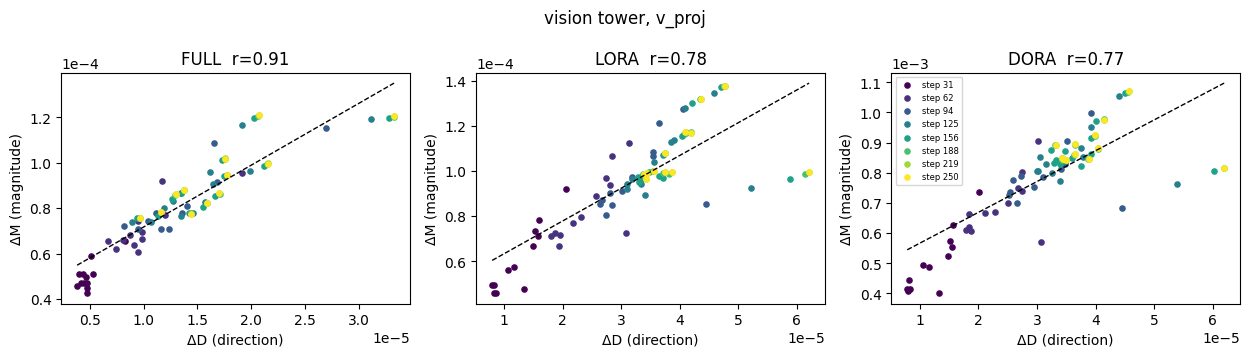

In [ ]:
from IPython.display import Image, display
for tower in ['text', 'vision']:
    for proj in ['q_proj', 'v_proj']:
        display(Image(dv.plot_scatter(OUT, tower=tower, proj=proj)))

## 7. Bonus: where does the adaptation happen?
Mean ΔD and ΔM per tower at the last checkpoint: does each method move the vision encoder, the connector or the language
model the most, and does DoRA's magnitude/direction split behave differently in the vision encoder?

In [7]:
from collections import defaultdict
for m in ['full', 'lora', 'dora']:
    p = os.path.join(OUT, f'stats_{m}.json')
    if not os.path.exists(p): continue
    st = json.load(open(p))['stats']; last = max(r['step'] for r in st)
    agg = defaultdict(list)
    for r in st:
        if r['step'] == last: agg[r['tower']].append(r)
    print(m, {t: dict(dD=f"{sum(r['dD'] for r in v)/len(v):.2e}", dM=f"{sum(r['dM'] for r in v)/len(v):.2e}", n=len(v))
              for t, v in agg.items()})

full {'vision': {'dD': '1.42e-05', 'dM': '1.10e-04', 'n': 48}, 'connector': {'dD': '7.49e-06', 'dM': '1.84e-04', 'n': 1}, 'text': {'dD': '4.42e-07', 'dM': '9.40e-05', 'n': 120}}
lora {'vision': {'dD': '3.13e-05', 'dM': '1.05e-04', 'n': 48}, 'connector': {'dD': '7.95e-06', 'dM': '1.49e-04', 'n': 1}, 'text': {'dD': '4.01e-06', 'dM': '2.32e-04', 'n': 120}}
dora {'vision': {'dD': '3.07e-05', 'dM': '8.76e-04', 'n': 48}, 'connector': {'dD': '7.15e-06', 'dM': '1.21e-03', 'n': 1}, 'text': {'dD': '3.86e-06', 'dM': '1.49e-03', 'n': 120}}


## 8. Bonus: tower ablation (DoRA on one tower only)
Same DoRA settings, but adapters only on the vision encoder (`dora_vision`) or only on the language model (`dora_text`);
the connector is frozen in both. Tests whether the large direction change seen in the vision encoder matters for DocVQA
accuracy, and how each tower behaves without the other adapting. ≈ 25 min train + 5 min eval per run.

In [8]:
import dataclasses
for t in ['vision', 'text']:
    c = dataclasses.replace(cfg, targets=t)
    name = dv.run_name(c, 'dora')
    if not os.path.exists(os.path.join(c.out_dir, f'stats_{name}.json')):
        model, proc = dv.train_method(c, 'dora')
        dv.evaluate_anls(c, model, proc, name)
        del model; gc.collect(); torch.cuda.empty_cache()
    elif dv.needs_eval(c, name):
        model, proc = dv.load_trained(c, 'dora')
        dv.evaluate_anls(c, model, proc, name)
        del model; gc.collect(); torch.cuda.empty_cache()
    else:
        print(f'{name}: trained and evaluated already')

dora_vision: trained and evaluated already
dora_text: trained and evaluated already


In [9]:
summary = dv.tower_summary(OUT)
corr_abl = dv.analyze(OUT, methods=('dora', 'dora_vision', 'dora_text'), proj_filter=None)
json.dump({'summary': summary, 'corr': corr_abl}, open(os.path.join(OUT, 'ablation.json'), 'w'), indent=1)

full         ANLS  57.07  vision: dM=1.10e-04 dD=1.42e-05  connector: dM=1.84e-04 dD=7.49e-06  text: dM=9.40e-05 dD=4.42e-07
lora         ANLS  56.73  vision: dM=1.05e-04 dD=3.13e-05  connector: dM=1.49e-04 dD=7.95e-06  text: dM=2.32e-04 dD=4.01e-06
dora         ANLS  57.50  vision: dM=8.76e-04 dD=3.07e-05  connector: dM=1.21e-03 dD=7.15e-06  text: dM=1.49e-03 dD=3.86e-06
dora_vision  ANLS  51.73  vision: dM=9.48e-04 dD=5.41e-05
dora_text    ANLS  55.33  text: dM=1.81e-03 dD=6.30e-06

== dora ==  group                     n  r_pooled  rho_pooled  r_within   r_final
          ALL                    1352    -0.399      -0.327    -0.531    -0.576
          connector/ALL             8     0.981       0.976       nan       nan
          connector/proj            8     0.981       0.976       nan       nan
          text/ALL                960     0.361       0.504     0.355     0.348
          text/k_proj             240     0.643       0.532     0.634     0.640
          text/o_proj       